# Direct multi-step fractal ablation experiment

This notebook drives the isolated `multistep_experiment` package cell by cell. The existing single-step baseline remains untouched. Model variant IDs name the full objective bundle: `value_only`, `value_fractional`, and `value_fractional_spectrum`; `spectrum` by itself names only the auxiliary head/task. Training cells are disabled by default and require an explicit Boolean switch. Change only `HORIZON` in `data_lake/config.json` to switch between the verified 10-step and 50-step designs, then restart the kernel and run from the top. Each horizon has its own parameter lock and output folder automatically. Saved cell outputs are intentionally cleared so displayed results always come from the current canonical run.

In [1]:
from pathlib import Path
import json
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'python':
    PROJECT_ROOT = PROJECT_ROOT.parent
PYTHON_ROOT = PROJECT_ROOT / 'python'
if str(PYTHON_ROOT) not in sys.path:
    sys.path.insert(0, str(PYTHON_ROOT))

from multistep_experiment.artifacts import load_locked_parameters
from multistep_experiment.comparison import compare_and_publish
from multistep_experiment.constants import MODEL_VARIANTS, SEEDS
from multistep_experiment.gradnorm import GradNormModel
from lineage import sha256_file
from multistep_experiment.experiment import (
    run_matrix,
    run_variant,
    tune_baseline,
    validate_design,
)

if 'calibrate_initial_losses' not in GradNormModel.__dict__:
    raise RuntimeError(
        'This kernel has the old GradNormModel loaded. Restart the kernel, then run this cell again.'
    )

I0000 00:00:1791324602.269076  989744 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791324602.418222  989744 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791324604.682120  989744 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
CONFIG_PATH = PROJECT_ROOT / 'data_lake' / 'config.json'
EXPERIMENT_ID = 'multistep_fractal_ablation_v1'
config = json.loads(CONFIG_PATH.read_text(encoding='utf-8'))
print({
    'horizon': config['HORIZON'],
    'evaluation_origin_count': config['EVALUATION_ORIGIN_COUNT'],
    'evaluation_origin_stride': config['EVALUATION_ORIGIN_STRIDE'],
    'minimum_train_origins': config['MIN_TRAIN_ORIGINS'],
    'experiment_id': EXPERIMENT_ID,
})

{'horizon': 50, 'evaluation_origin_count': 5, 'evaluation_origin_stride': 10, 'minimum_train_origins': 50, 'experiment_id': 'multistep_fractal_ablation_v1'}


## 1. Validate contracts without training

This reads the aligned data, validates lineage and leakage boundaries, and creates purged fold indexes. It does not run feature selection, Optuna, or model fitting.

In [3]:
CANDIDATE_LOOKBACKS = (3, 4, 5, 6, 8, 10)
designs = {
    lookback: validate_design(CONFIG_PATH, lookback=lookback)
    for lookback in CANDIDATE_LOOKBACKS
}
display({
    lookback: {
        'samples': design['samples'],
        'development_samples': design['development_samples'],
        'fold_samples': [
            (fold['train_samples'], fold['validation_samples'])
            for fold in design['folds']
        ],
        'feature_target_leakage': design['feature_target_leakage'],
    }
    for lookback, design in designs.items()
})

{3: {'samples': 209,
  'development_samples': 119,
  'fold_samples': [(50, 7), (57, 7), (64, 6)],
  'feature_target_leakage': False},
 4: {'samples': 208,
  'development_samples': 118,
  'fold_samples': [(50, 7), (57, 6), (63, 6)],
  'feature_target_leakage': False},
 5: {'samples': 207,
  'development_samples': 117,
  'fold_samples': [(50, 6), (56, 6), (62, 6)],
  'feature_target_leakage': False},
 6: {'samples': 206,
  'development_samples': 116,
  'fold_samples': [(50, 6), (56, 6), (62, 5)],
  'feature_target_leakage': False},
 8: {'samples': 204,
  'development_samples': 114,
  'fold_samples': [(50, 5), (55, 5), (60, 5)],
  'feature_target_leakage': False},
 10: {'samples': 202,
  'development_samples': 112,
  'fold_samples': [(50, 5), (55, 4), (59, 4)],
  'feature_target_leakage': False}}

## 2. Tune the value-only baseline once for the current horizon

Run this after selecting `HORIZON=10` or `HORIZON=50` in `config.json` and reviewing the validation above. The remaining rolling-origin settings are already feasible for both verified horizons. The resulting horizon-specific lock is shared by all three objective bundles. Fold-local feature rankings are cached for every sampled lookback; their internal permutation split is target-interval purged when it retains at least 10 training and 5 validation samples, otherwise the outer-training-only impurity fallback is recorded. The median pruner reports only comparable completed-fold running RMSE and never treats epochs from restarted fold models as one continuous resource.

In [4]:
RUN_TUNING = True
if RUN_TUNING:
    tuning_result = tune_baseline(
        config_path=CONFIG_PATH,
        experiment_id=EXPERIMENT_ID,
        n_trials=40,
        seed=42,
    )
    display(tuning_result)
else:
    print('Tuning disabled; set RUN_TUNING=True to start Optuna explicitly.')

/home/it_dash/Water-Analyzer-Ukr/.venv-linux/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-10-06 18:10:13,349] A new study created in memory with name: multistep_fractal_ablation_v1_horizon_50_baseline
I0000 00:00:1791324617.465698  989985 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791324617.466772  989986 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791324617.505693  989992 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791324617.539454  989988 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791324617.591813  989986 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use

[I 2026-10-06 18:11:02,918] Trial 1 finished with value: 0.5947862466176351 and parameters: {'encoder_units': 64, 'decoder_units': 64, 'dropout': 0.0, 'learning_rate': 0.0007896186801026692, 'batch_size': 32, 'lookback': 3, 'top_k': 10}. Best is trial 1 with value: 0.5947862466176351.
[I 2026-10-06 18:11:33,446] Trial 2 finished with value: 0.5649448235829672 and parameters: {'encoder_units': 64, 'decoder_units': 32, 'dropout': 0.3, 'learning_rate': 0.0020978213384576817, 'batch_size': 16, 'lookback': 10, 'top_k': 12}. Best is trial 2 with value: 0.5649448235829672.
[I 2026-10-06 18:11:53,379] Trial 3 finished with value: 0.6040189663569132 and parameters: {'encoder_units': 16, 'decoder_units': 32, 'dropout': 0.25, 'learning_rate': 0.0013780336485752, 'batch_size': 16, 'lookback': 3, 'top_k': 8}. Best is trial 2 with value: 0.5649448235829672.
[I 2026-10-06 18:12:16,761] Trial 4 finished with value: 0.5953147411346436 and parameters: {'encoder_units': 64, 'decoder_units': 32, 'dropout'

{'objective': 'mean purged-fold global value RMSE',
 'direction': 'minimize',
 'horizon': 50,
 'tuning_variant': 'value_only',
 'tuning_seed': 42,
 'n_trials': 40,
 'n_splits': 3,
 'completed_trials': 25,
 'pruned_trials': 15,
 'pruner': {'name': 'MedianPruner',
  'resource': 'completed purged folds',
  'n_startup_trials': 5,
  'n_warmup_steps': 1,
  'interval_steps': 1,
  'monitor': 'running mean original-scale value_rmse'},
 'feature_ranking_cache': {'enabled': True,
  'scope': 'in-memory per tuning run, lookback, fold, and seed',
  'cached_lookbacks': [3, 4, 5, 6, 8, 10]},
 'best_value': 0.5458653370539347,
 'parameters': {'encoder_units': 64,
  'decoder_units': 64,
  'dropout': 0.1,
  'learning_rate': 0.0006419892064825209,
  'batch_size': 16,
  'lookback': 10,
  'top_k': 10},
 'config_checksum': 'f2fb413dcebb72d4d6009645749749522162ae47fa2a51141032a9caa67758b0',
 'config_snapshot': {'RAW_FOLDER': 'data_lake/raw/source_data',
  'BRONZE_FOLDER': 'data_lake/bronze/combined',
  'CURAT

In [5]:
try:
    locked = load_locked_parameters(CONFIG_PATH, EXPERIMENT_ID)
    if locked.get('config_checksum') != sha256_file(CONFIG_PATH):
        print(
            'The parameter lock belongs to a different configuration. '
            'Enable RUN_TUNING for the current horizon before running models.'
        )
        locked = None
    else:
        display(locked)
except FileNotFoundError as error:
    print(error)

{'objective': 'mean purged-fold global value RMSE',
 'direction': 'minimize',
 'horizon': 50,
 'tuning_variant': 'value_only',
 'tuning_seed': 42,
 'n_trials': 40,
 'n_splits': 3,
 'completed_trials': 25,
 'pruned_trials': 15,
 'pruner': {'name': 'MedianPruner',
  'resource': 'completed purged folds',
  'n_startup_trials': 5,
  'n_warmup_steps': 1,
  'interval_steps': 1,
  'monitor': 'running mean original-scale value_rmse'},
 'feature_ranking_cache': {'enabled': True,
  'scope': 'in-memory per tuning run, lookback, fold, and seed',
  'cached_lookbacks': [3, 4, 5, 6, 8, 10]},
 'best_value': 0.5458653370539347,
 'parameters': {'encoder_units': 64,
  'decoder_units': 64,
  'dropout': 0.1,
  'learning_rate': 0.0006419892064825209,
  'batch_size': 16,
  'lookback': 10,
  'top_k': 10},
 'config_checksum': 'f2fb413dcebb72d4d6009645749749522162ae47fa2a51141032a9caa67758b0',
 'config_snapshot': {'RAW_FOLDER': 'data_lake/raw/source_data',
  'BRONZE_FOLDER': 'data_lake/bronze/combined',
  'CURAT

## 3. Run one experiment cell

Use this for controlled inspection before launching the full matrix. `value_only`, `value_fractional`, and `value_fractional_spectrum` select the baseline, fractional-difference, and fractional-difference-plus-spectrum objective bundles.

In [6]:
RUN_SINGLE = False
VARIANT = 'value_only'
SEED = 42
if RUN_SINGLE:
    single_outputs = run_variant(
        config_path=CONFIG_PATH,
        experiment_id=EXPERIMENT_ID,
        variant=VARIANT,
        seed=SEED,
        d_bootstrap_repeats=0,
    )
    display(single_outputs)
else:
    print('Single run disabled; set RUN_SINGLE=True to train explicitly.')

Single run disabled; set RUN_SINGLE=True to train explicitly.


## 4. Run the complete same-horizon matrix

This is intentionally the last and most expensive cell. Run it separately for horizon 10 and horizon 50 after tuning the baseline for the selected horizon. The horizon-specific folder keeps both experiments isolated even when the same `EXPERIMENT_ID` is used.

In [7]:
RUN_FULL_MATRIX = True
if RUN_FULL_MATRIX:
    matrix_outputs = run_matrix(
        config_path=CONFIG_PATH,
        experiment_id=EXPERIMENT_ID,
        variants=MODEL_VARIANTS,
        seeds=SEEDS,
        d_bootstrap_repeats=0,
    )
    display(matrix_outputs)
else:
    print('Full matrix disabled; set RUN_FULL_MATRIX=True to train explicitly.')

I0000 00:00:1791325582.386452 1212048 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791325582.386453 1212045 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791325582.386453 1212051 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791325582.528834 1212052 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791325582.548965 1212045 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791325582.549067 1212048 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: A

[{'forecast': PosixPath('/home/it_dash/Water-Analyzer-Ukr/data_lake/forecasts/experiments/multistep_fractal_ablation_v1/horizon_50/model_value_only/seed_7/forecast.csv'),
  'fold_metrics': PosixPath('/home/it_dash/Water-Analyzer-Ukr/data_lake/forecasts/experiments/multistep_fractal_ablation_v1/horizon_50/model_value_only/seed_7/fold_metrics.csv'),
  'training_history': PosixPath('/home/it_dash/Water-Analyzer-Ukr/data_lake/forecasts/experiments/multistep_fractal_ablation_v1/horizon_50/model_value_only/seed_7/training_history.csv'),
  'metadata': PosixPath('/home/it_dash/Water-Analyzer-Ukr/data_lake/forecasts/experiments/multistep_fractal_ablation_v1/horizon_50/model_value_only/seed_7/metadata.json'),
  'model': PosixPath('/home/it_dash/Water-Analyzer-Ukr/data_lake/forecasts/experiments/multistep_fractal_ablation_v1/horizon_50/model_value_only/seed_7/model.keras'),
  'forecast_lineage': PosixPath('/home/it_dash/Water-Analyzer-Ukr/data_lake/forecasts/experiments/multistep_fractal_ablation

## 5. Compare completed runs within the current horizon

This cell performs no training. It requires the complete five-seed matrix and publishes per-seed and per-origin accuracy diagnostics, descriptive seed intervals, paired candidate-minus-baseline deltas, and recorded training durations. It does not report an independence-based p-value because the rolling windows overlap. Missing learning-time metadata is treated as an incomplete run.

In [8]:
RUN_COMPARISON = True
if RUN_COMPARISON:
    comparison_outputs = compare_and_publish(
        config_path=CONFIG_PATH, experiment_id=EXPERIMENT_ID
    )
    display(comparison_outputs)
else:
    print('Comparison disabled until the experiment matrix is complete.')

{'runs': PosixPath('/home/it_dash/Water-Analyzer-Ukr/data_lake/forecasts/experiments/multistep_fractal_ablation_v1/horizon_50/comparison_runs.csv'),
 'origins': PosixPath('/home/it_dash/Water-Analyzer-Ukr/data_lake/forecasts/experiments/multistep_fractal_ablation_v1/horizon_50/comparison_origins.csv'),
 'summary': PosixPath('/home/it_dash/Water-Analyzer-Ukr/data_lake/forecasts/experiments/multistep_fractal_ablation_v1/horizon_50/comparison_summary.csv'),
 'paired': PosixPath('/home/it_dash/Water-Analyzer-Ukr/data_lake/forecasts/experiments/multistep_fractal_ablation_v1/horizon_50/comparison_paired.csv'),
 'runs_lineage': PosixPath('/home/it_dash/Water-Analyzer-Ukr/data_lake/forecasts/experiments/multistep_fractal_ablation_v1/horizon_50/comparison_runs.csv.lineage.json'),
 'origins_lineage': PosixPath('/home/it_dash/Water-Analyzer-Ukr/data_lake/forecasts/experiments/multistep_fractal_ablation_v1/horizon_50/comparison_origins.csv.lineage.json'),
 'summary_lineage': PosixPath('/home/it_da

In [9]:
from pathlib import Path
import pandas as pd

ROOT = (
    PROJECT_ROOT / 'data_lake' / 'forecasts' / 'experiments'
    / EXPERIMENT_ID / f"horizon_{config['HORIZON']}"
)

comparison_paths = {
    'runs': ROOT / 'comparison_runs.csv',
    'origins': ROOT / 'comparison_origins.csv',
    'summary': ROOT / 'comparison_summary.csv',
    'paired': ROOT / 'comparison_paired.csv',
}
COMPARISON_READY = all(path.is_file() for path in comparison_paths.values())
if COMPARISON_READY:
    runs = pd.read_csv(comparison_paths['runs'])
    origins = pd.read_csv(comparison_paths['origins'])
    summary = pd.read_csv(comparison_paths['summary'])
    paired = pd.read_csv(comparison_paths['paired'])
    display(runs)
    display(origins)
    display(summary)
    display(paired)
else:
    runs = origins = summary = paired = None
    missing = [str(path) for path in comparison_paths.values() if not path.is_file()]
    print('Comparison artifacts are not ready for this horizon:')
    print(*missing, sep='\n')

,variant,seed,horizon,origins,forecast_points,value_rmse,value_mae,forecast_bias,median_absolute_error,p90_absolute_error,within_horizon_direction_accuracy,cross_validation_training_seconds,final_training_seconds,total_training_seconds,total_trained_epochs
0,value_fractional,7,50,5,250,1.038191,0.730784,-0.404461,0.478376,1.529578,0.497959,211.337853,58.909110,270.246963,111
1,value_fractional,21,50,5,250,1.046119,0.733237,-0.440719,0.489014,1.587944,0.493878,213.136212,56.852300,269.988512,111
2,value_fractional,42,50,5,250,1.196273,0.871254,-0.709939,0.641376,1.857471,0.489796,267.135583,65.333402,332.468985,135
3,value_fractional,84,50,5,250,1.362501,1.036048,-0.979211,0.891276,2.200070,0.477551,224.605157,61.472257,286.077414,116
4,value_fractional,123,50,5,250,1.133459,0.810772,-0.609807,0.574872,1.742304,0.493878,234.045242,75.046399,309.091642,125
5,value_fractional_spectrum,7,50,5,250,1.049803,0.737634,-0.440639,0.481758,1.577871,0.497959,280.733791,73.323238,354.057029,111
6,value_fractional_spectrum,21,50,5,250,1.060432,0.743568,-0.476315,0.500774,1.621454,0.477551,290.275937,75.102037,365.377974,116
7,value_fractional_spectrum,42,50,5,250,1.137268,0.813914,-0.615623,0.566953,1.777156,0.493878,342.994270,81.042679,424.036949,132
8,value_fractional_spectrum,84,50,5,250,1.354249,1.028677,-0.970955,0.876460,2.188382,0.477551,453.410451,138.545862,591.956313,182
9,value_fractional_spectrum,123,50,5,250,1.132025,0.807197,-0.604059,0.553517,1.786230,0.481633,363.739528,96.613918,460.353446,143


,variant,seed,forecast_origin,forecast_origin_date,value_rmse,value_mae,forecast_bias,p90_absolute_error,within_horizon_direction_accuracy
0,value_fractional,7,319,2015-03-18,1.045968,0.708573,-0.528026,1.735260,0.510204
1,value_fractional,7,329,2015-08-25,1.103238,0.795819,-0.551919,1.936021,0.489796
2,value_fractional,7,339,2016-01-21,1.083300,0.798403,-0.380611,1.580955,0.510204
3,value_fractional,7,349,2016-06-22,1.086618,0.733493,-0.407426,1.591166,0.489796
4,value_fractional,7,359,2016-11-22,0.850730,0.617634,-0.154320,1.207592,0.489796
...,...,...,...,...,...,...,...,...,...
70,value_only,123,319,2015-03-18,1.143132,0.817222,-0.698242,1.918283,0.530612
71,value_only,123,329,2015-08-25,1.212457,0.913178,-0.751452,2.108573,0.489796
72,value_only,123,339,2016-01-21,1.179707,0.849537,-0.603842,1.802677,0.510204
73,value_only,123,349,2016-06-22,1.195643,0.814980,-0.650661,1.837112,0.489796


,variant,seed_runs,rolling_origins_per_seed,mean_value_rmse,std_value_rmse_across_seeds,median_value_rmse,mean_value_mae,mean_forecast_bias,mean_p90_absolute_error,mean_within_horizon_direction_accuracy,mean_total_training_seconds,median_total_training_seconds,mean_total_trained_epochs,descriptive_seed_ci95_low,descriptive_seed_ci95_high,inference_note,mean_rmse_change_vs_baseline_pct,mean_training_time_ratio_vs_baseline
0,value_fractional,5,5,1.155309,0.132969,1.133459,0.836419,-0.628827,1.783473,0.490612,293.574703,286.077414,119.6,0.990205,1.320412,Seed interval measures optimization variabilit...,-0.820893,10.076004
1,value_fractional_spectrum,5,5,1.146755,0.122691,1.132025,0.826198,-0.621518,1.790219,0.485714,439.156342,424.036949,136.8,0.994415,1.299096,Seed interval measures optimization variabilit...,-1.555170,15.072623
2,value_only,5,5,1.164871,0.138434,1.134280,0.845640,-0.647594,1.807020,0.495510,29.136026,29.260764,116.8,0.992982,1.336760,Seed interval measures optimization variabilit...,0.000000,1.000000


,candidate,paired_seeds,paired_origins,paired_seed_origins,mean_origin_rmse_delta_candidate_minus_baseline,median_origin_rmse_delta_candidate_minus_baseline,wins_lower_origin_rmse,win_rate_lower_origin_rmse,mean_origin_rmse_change_pct,inference_note
0,value_fractional,5,5,25,-0.009440,-0.002713,18,0.72,-0.755047,Descriptive matched seed-origin effect; no ind...
1,value_fractional_spectrum,5,5,25,-0.017958,0.002368,10,0.40,-1.351227,Descriptive matched seed-origin effect; no ind...


In [10]:
rmse = None
if COMPARISON_READY:
    rmse = runs.pivot(
        index='seed',
        columns='variant',
        values='value_rmse',
    )
    for candidate in ('value_fractional', 'value_fractional_spectrum'):
        rmse[f'{candidate}_delta'] = rmse[candidate] - rmse['value_only']
        rmse[f'{candidate}_change_pct'] = (
            100 * rmse[f'{candidate}_delta'] / rmse['value_only']
        )
    display(rmse)
else:
    print('RMSE comparison skipped until comparison artifacts are ready.')

variant,value_fractional,value_fractional_spectrum,value_only,value_fractional_delta,value_fractional_change_pct,value_fractional_spectrum_delta,value_fractional_spectrum_change_pct
seed,,,,,,,
7,1.038191,1.049803,1.035308,0.002883,0.278448,0.014495,1.400021
21,1.046119,1.060432,1.050119,-0.004000,-0.380877,0.010313,0.982126
42,1.196273,1.137268,1.239160,-0.042888,-3.461025,-0.101892,-8.222684
84,1.362501,1.354249,1.365488,-0.002986,-0.218691,-0.011239,-0.823084
123,1.133459,1.132025,1.134280,-0.000821,-0.072384,-0.002255,-0.198828


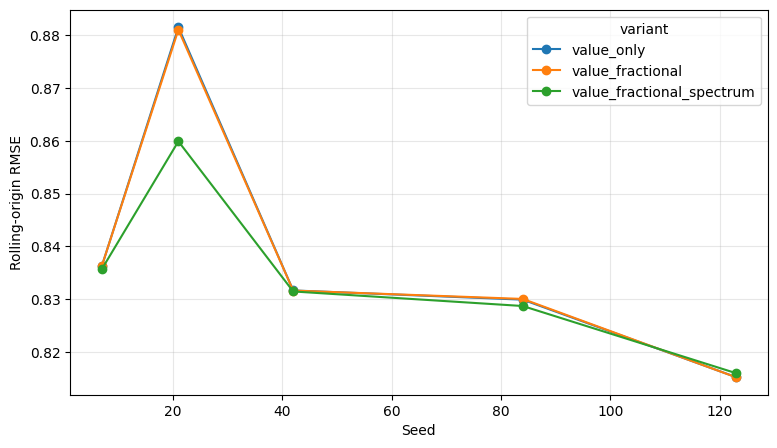

In [11]:
import matplotlib.pyplot as plt

if rmse is not None:
    ax = rmse[[
        'value_only', 'value_fractional', 'value_fractional_spectrum'
    ]].plot(
        marker='o',
        figsize=(9, 5),
    )
    ax.set_ylabel('Rolling-origin RMSE')
    ax.set_xlabel('Seed')
    ax.grid(alpha=0.3)
    plt.show()
else:
    print('RMSE plot skipped until comparison artifacts are ready.')

## 6. Diagnostic comparison dashboard

The cells below perform analysis only; they never train a model. The primary criterion remains global value RMSE in the original measurement units. MAE, signed bias, 90th-percentile absolute error, and within-horizon directional accuracy are secondary diagnostics. Runtime measures computational cost, not forecast quality. All comparisons are restricted to the currently configured horizon.

In [11]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from multistep_experiment.constants import canonical_variant

VARIANT_LABELS = {
    'value_only': 'Value only',
    'value_fractional': 'Value + fractional',
    'value_fractional_spectrum': 'Value + fractional + spectrum',
}
VARIANT_COLORS = {
    'value_only': '#4C78A8',
    'value_fractional': '#F58518',
    'value_fractional_spectrum': '#54A24B',
}

def artifact_path(variant, seed, filename):
    path = ROOT / f'model_{variant}' / f'seed_{int(seed)}' / filename
    if not path.is_file():
        raise FileNotFoundError(f'Missing {filename} for {variant}, seed {seed}: {path}')
    return path

def direction_accuracy(frame):
    matches = []
    for _, origin in frame.groupby('forecast_origin', sort=True):
        origin = origin.sort_values('horizon_step')
        actual_change = np.diff(origin['actual'].to_numpy(dtype=float))
        forecast_change = np.diff(origin['forecast'].to_numpy(dtype=float))
        if len(actual_change):
            matches.extend(np.sign(actual_change) == np.sign(forecast_change))
    return float(np.mean(matches)) if matches else np.nan

forecast_panel = None
run_diagnostics = None
if COMPARISON_READY:
    runs['variant'] = runs['variant'].map(canonical_variant)
    origins['variant'] = origins['variant'].map(canonical_variant)
    panel_parts = []
    diagnostic_rows = []
    completed_seeds = sorted(runs['seed'].astype(int).unique())
    for variant in MODEL_VARIANTS:
        for seed in completed_seeds:
            forecast_file = artifact_path(variant, seed, 'forecast.csv')
            metadata_file = artifact_path(variant, seed, 'metadata.json')
            forecast = pd.read_csv(forecast_file).sort_values(
                ['forecast_origin', 'horizon_step']
            )
            metadata = json.loads(metadata_file.read_text(encoding='utf-8'))
            timing = metadata.get('timing')
            required_timing = {
                'cross_validation_training_seconds',
                'final_training_seconds',
                'total_training_seconds',
                'total_trained_epochs',
            }
            if not isinstance(timing, dict) or not required_timing.issubset(timing):
                raise ValueError(f'Incomplete elapsed learning-time metadata: {metadata_file}')
            forecast['variant'] = variant
            forecast['seed'] = seed
            forecast['error'] = forecast['forecast'] - forecast['actual']
            forecast['absolute_error'] = forecast['error'].abs()
            panel_parts.append(forecast)
            error = forecast['error'].to_numpy(dtype=float)
            absolute_error = np.abs(error)
            total_seconds = float(timing['total_training_seconds'])
            total_epochs = int(timing['total_trained_epochs'])
            diagnostic_rows.append({
                'variant': variant,
                'seed': seed,
                'rmse': np.sqrt(np.mean(np.square(error))),
                'mae': np.mean(absolute_error),
                'bias': np.mean(error),
                'p90_absolute_error': np.quantile(absolute_error, 0.90),
                'direction_accuracy': direction_accuracy(forecast),
                'training_seconds': total_seconds,
                'trained_epochs': total_epochs,
                'seconds_per_epoch': total_seconds / total_epochs,
            })
    forecast_panel = pd.concat(panel_parts, ignore_index=True)
    run_diagnostics = pd.DataFrame(diagnostic_rows)
    display(run_diagnostics)
else:
    print('Dashboard skipped until comparison artifacts are ready.')

,variant,seed,rmse,mae,bias,p90_absolute_error,direction_accuracy,training_seconds,trained_epochs,seconds_per_epoch
0,value_only,7,1.035308,0.728709,-0.396225,1.519615,0.497959,29.260764,109,0.268447
1,value_only,21,1.050119,0.736232,-0.450186,1.597470,0.497959,29.834010,111,0.268775
2,value_only,42,1.239160,0.913151,-0.795738,1.969601,0.502041,30.270145,131,0.231070
3,value_only,84,1.365488,1.039312,-0.983079,2.202342,0.485714,27.550087,114,0.241667
4,value_only,123,1.134280,0.810796,-0.612742,1.746072,0.493878,28.765124,119,0.241724
5,value_fractional,7,1.038191,0.730784,-0.404461,1.529578,0.497959,270.246963,111,2.434657
6,value_fractional,21,1.046119,0.733237,-0.440719,1.587944,0.493878,269.988512,111,2.432329
7,value_fractional,42,1.196273,0.871254,-0.709939,1.857471,0.489796,332.468985,135,2.462733
8,value_fractional,84,1.362501,1.036048,-0.979211,2.200070,0.477551,286.077414,116,2.466185
9,value_fractional,123,1.133459,0.810772,-0.609807,1.742304,0.493878,309.091642,125,2.472733


### 6.1 Ranked overview

Use mean RMSE to rank the models. The seed standard deviation shows optimization stability. Negative bias means underprediction; positive bias means overprediction. Direction accuracy measures only step-to-step movements inside each forecast horizon and is not a substitute for RMSE.

In [12]:
diagnostic_summary = None
if run_diagnostics is not None:
    diagnostic_summary = (
        run_diagnostics.groupby('variant', sort=False)
        .agg(
            mean_rmse=('rmse', 'mean'),
            seed_rmse_std=('rmse', 'std'),
            mean_mae=('mae', 'mean'),
            mean_bias=('bias', 'mean'),
            mean_p90_absolute_error=('p90_absolute_error', 'mean'),
            mean_direction_accuracy=('direction_accuracy', 'mean'),
            mean_training_seconds=('training_seconds', 'mean'),
            mean_seconds_per_epoch=('seconds_per_epoch', 'mean'),
        )
        .reset_index()
    )
    baseline_rmse = diagnostic_summary.loc[
        diagnostic_summary['variant'] == 'value_only', 'mean_rmse'
    ].iloc[0]
    diagnostic_summary['rmse_change_vs_baseline_pct'] = (
        100 * (diagnostic_summary['mean_rmse'] - baseline_rmse) / baseline_rmse
    )
    diagnostic_summary['direction_accuracy_pct'] = (
        100 * diagnostic_summary['mean_direction_accuracy']
    )
    diagnostic_summary['mean_training_minutes'] = (
        diagnostic_summary['mean_training_seconds'] / 60
    )
    diagnostic_summary['rmse_rank'] = (
        diagnostic_summary['mean_rmse'].rank(method='min').astype(int)
    )
    diagnostic_summary['model'] = diagnostic_summary['variant'].map(VARIANT_LABELS)
    display(
        diagnostic_summary[[
            'rmse_rank', 'model', 'mean_rmse', 'seed_rmse_std',
            'rmse_change_vs_baseline_pct', 'mean_mae', 'mean_bias',
            'mean_p90_absolute_error', 'direction_accuracy_pct',
            'mean_training_minutes', 'mean_seconds_per_epoch',
        ]].sort_values('rmse_rank').style.format({
            'mean_rmse': '{:.4f}',
            'seed_rmse_std': '{:.4f}',
            'rmse_change_vs_baseline_pct': '{:+.2f}%',
            'mean_mae': '{:.4f}',
            'mean_bias': '{:+.4f}',
            'mean_p90_absolute_error': '{:.4f}',
            'direction_accuracy_pct': '{:.1f}%',
            'mean_training_minutes': '{:.2f}',
            'mean_seconds_per_epoch': '{:.2f}',
        })
    )

,rmse_rank,model,mean_rmse,seed_rmse_std,rmse_change_vs_baseline_pct,mean_mae,mean_bias,mean_p90_absolute_error,direction_accuracy_pct,mean_training_minutes,mean_seconds_per_epoch
2,1,Value + fractional + spectrum,1.1468,0.1227,-1.56%,0.8262,-0.6215,1.7902,48.6%,7.32,3.20
1,2,Value + fractional,1.1553,0.1330,-0.82%,0.8364,-0.6288,1.7835,49.1%,4.89,2.45
0,3,Value only,1.1649,0.1384,+0.00%,0.8456,-0.6476,1.8070,49.6%,0.49,0.25


### 6.2 Seed-paired RMSE and baseline deltas

Each line on the left is one seed, so lower movement from the baseline is an improvement under the same initialization seed. The right panel makes the paired differences explicit: values below zero favor the candidate. Five seeds describe optimization variability but do not create five independent time-series datasets.

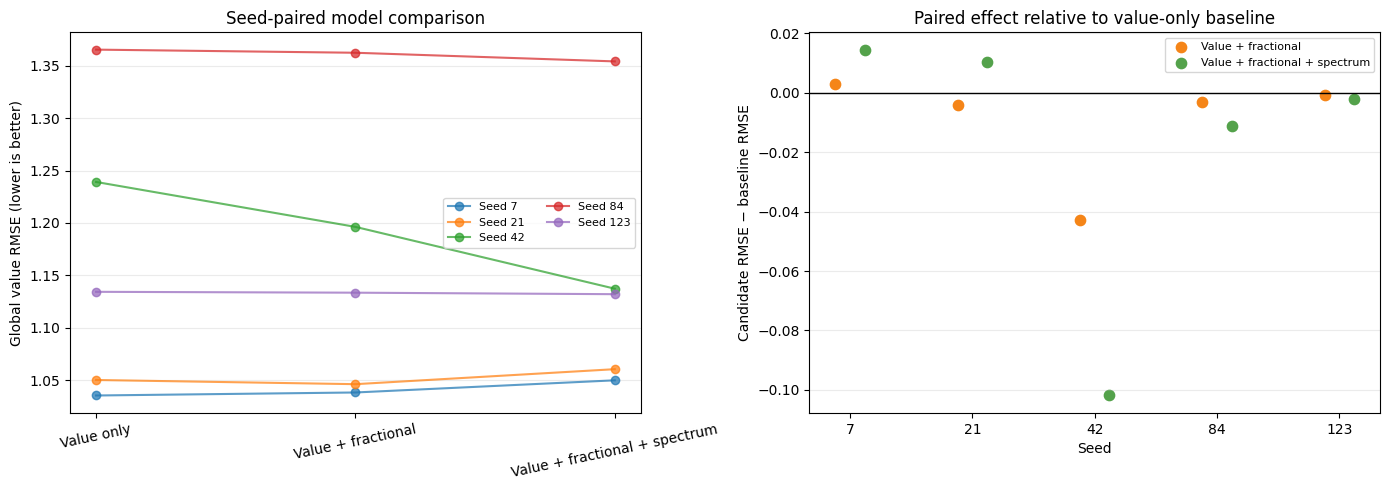

In [13]:
if run_diagnostics is not None:
    order = list(MODEL_VARIANTS)
    paired_rmse = run_diagnostics.pivot(index='seed', columns='variant', values='rmse')[order]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    x = np.arange(len(order))
    for seed, row in paired_rmse.iterrows():
        axes[0].plot(x, row.to_numpy(), marker='o', alpha=0.72, label=f'Seed {seed}')
    axes[0].set_xticks(x, [VARIANT_LABELS[item] for item in order], rotation=12)
    axes[0].set_ylabel('Global value RMSE (lower is better)')
    axes[0].set_title('Seed-paired model comparison')
    axes[0].grid(axis='y', alpha=0.25)
    axes[0].legend(fontsize=8, ncol=2)

    candidates = order[1:]
    offsets = np.linspace(-0.12, 0.12, len(candidates))
    for offset, candidate in zip(offsets, candidates):
        delta = paired_rmse[candidate] - paired_rmse['value_only']
        axes[1].scatter(
            np.arange(len(delta)) + offset, delta, s=55,
            color=VARIANT_COLORS[candidate], label=VARIANT_LABELS[candidate],
        )
    axes[1].axhline(0, color='black', linewidth=1)
    axes[1].set_xticks(np.arange(len(paired_rmse)), paired_rmse.index.astype(str))
    axes[1].set_xlabel('Seed')
    axes[1].set_ylabel('Candidate RMSE − baseline RMSE')
    axes[1].set_title('Paired effect relative to value-only baseline')
    axes[1].grid(axis='y', alpha=0.25)
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

### 6.3 Error by forecast step

This is the most useful diagnostic for a direct multi-step model. It shows whether an auxiliary objective helps near-term predictions, later predictions, or neither. Curves are the mean step-specific RMSE across seeds; shaded bands are one seed standard deviation and are descriptive rather than confidence intervals.

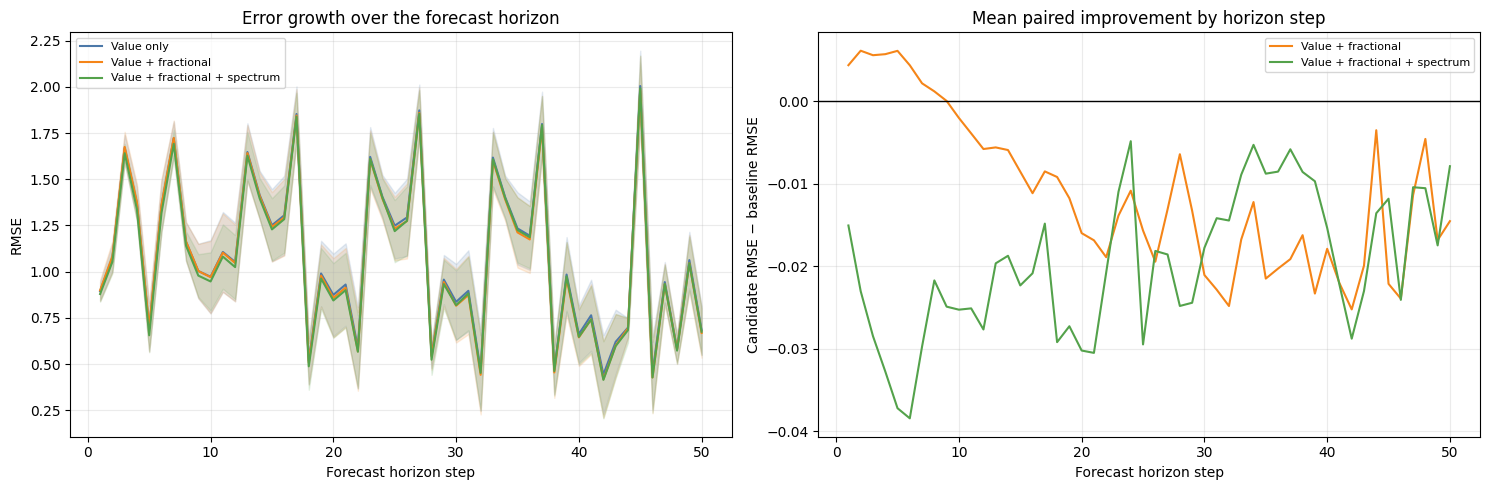

In [14]:
step_by_run = None
if forecast_panel is not None:
    step_by_run = (
        forecast_panel.groupby(['variant', 'seed', 'horizon_step'], as_index=False)
        .agg(step_mse=('error', lambda values: np.mean(np.square(values))))
    )
    step_by_run['step_rmse'] = np.sqrt(step_by_run.pop('step_mse'))
    step_summary = (
        step_by_run.groupby(['variant', 'horizon_step'])['step_rmse']
        .agg(['mean', 'std']).reset_index()
    )
    baseline_steps = step_by_run.loc[
        step_by_run['variant'] == 'value_only',
        ['seed', 'horizon_step', 'step_rmse'],
    ].rename(columns={'step_rmse': 'baseline_rmse'})

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for variant in MODEL_VARIANTS:
        frame = step_summary[step_summary['variant'] == variant]
        steps = frame['horizon_step'].to_numpy()
        mean = frame['mean'].to_numpy()
        std = frame['std'].fillna(0).to_numpy()
        axes[0].plot(steps, mean, color=VARIANT_COLORS[variant], label=VARIANT_LABELS[variant])
        axes[0].fill_between(steps, mean - std, mean + std, color=VARIANT_COLORS[variant], alpha=0.14)
    axes[0].set_xlabel('Forecast horizon step')
    axes[0].set_ylabel('RMSE')
    axes[0].set_title('Error growth over the forecast horizon')
    axes[0].grid(alpha=0.25)
    axes[0].legend(fontsize=8)

    for variant in MODEL_VARIANTS[1:]:
        candidate_steps = step_by_run.loc[
            step_by_run['variant'] == variant,
            ['seed', 'horizon_step', 'step_rmse'],
        ]
        matched = candidate_steps.merge(
            baseline_steps, on=['seed', 'horizon_step'], validate='one_to_one'
        )
        matched['delta'] = matched['step_rmse'] - matched['baseline_rmse']
        delta = matched.groupby('horizon_step')['delta'].agg(['mean', 'std']).reset_index()
        axes[1].plot(
            delta['horizon_step'], delta['mean'],
            color=VARIANT_COLORS[variant], label=VARIANT_LABELS[variant],
        )
    axes[1].axhline(0, color='black', linewidth=1)
    axes[1].set_xlabel('Forecast horizon step')
    axes[1].set_ylabel('Candidate RMSE − baseline RMSE')
    axes[1].set_title('Mean paired improvement by horizon step')
    axes[1].grid(alpha=0.25)
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

### 6.4 Learning cost and error character

Total training time includes model construction, initial GradNorm calibration where applicable, and all cross-validation plus final-fit calls. It intentionally excludes cached preprocessing and artifact writing. Runtime is machine-dependent, so compare models from the same matrix execution. The remaining panels separate typical error (MAE), large error (P90), systematic offset (absolute bias), and trend-direction behavior.

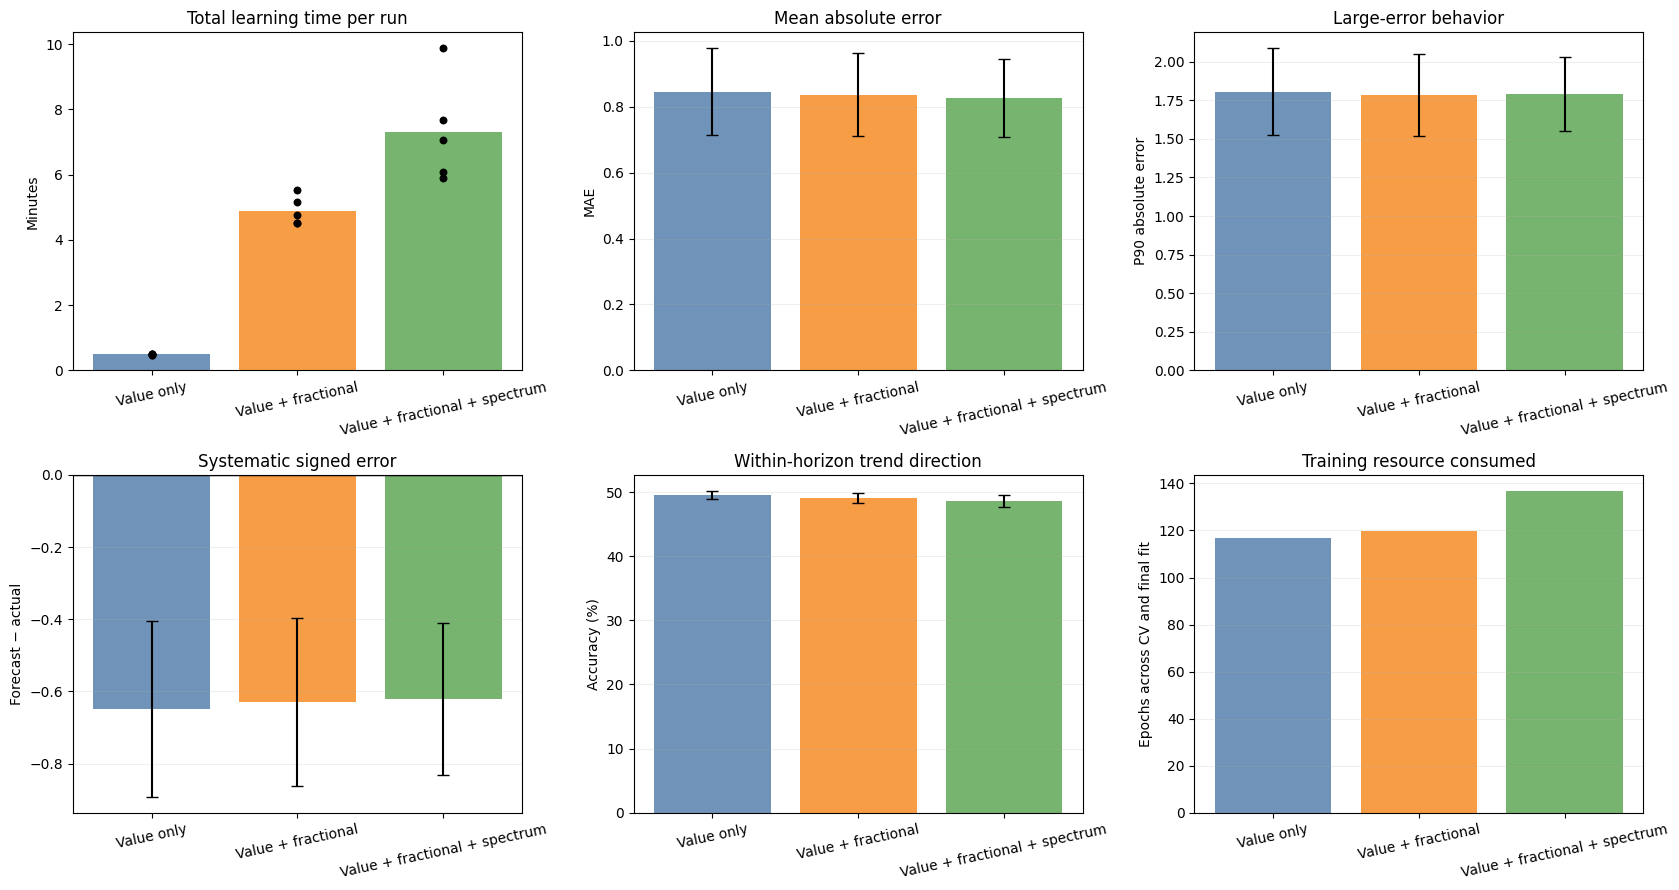

In [15]:
if run_diagnostics is not None:
    order = list(MODEL_VARIANTS)
    labels = [VARIANT_LABELS[item] for item in order]
    colors = [VARIANT_COLORS[item] for item in order]
    fig, axes = plt.subplots(2, 3, figsize=(17, 9))

    for position, variant in enumerate(order):
        values = run_diagnostics.loc[
            run_diagnostics['variant'] == variant, 'training_seconds'
        ] / 60
        axes[0, 0].bar(position, values.mean(), color=VARIANT_COLORS[variant], alpha=0.8)
        axes[0, 0].scatter(np.repeat(position, len(values)), values, color='black', s=22, zorder=3)
    axes[0, 0].set_xticks(range(len(order)), labels, rotation=12)
    axes[0, 0].set_ylabel('Minutes')
    axes[0, 0].set_title('Total learning time per run')

    metrics = [
        ('mae', 'Mean absolute error', 'MAE', False),
        ('p90_absolute_error', 'Large-error behavior', 'P90 absolute error', False),
        ('bias', 'Systematic signed error', 'Forecast − actual', True),
        ('direction_accuracy', 'Within-horizon trend direction', 'Accuracy (%)', False),
    ]
    for axis, (column, title, ylabel, signed) in zip(axes.flat[1:5], metrics):
        means = run_diagnostics.groupby('variant')[column].mean().reindex(order)
        stds = run_diagnostics.groupby('variant')[column].std().reindex(order)
        if column == 'direction_accuracy':
            means, stds = 100 * means, 100 * stds
        axis.bar(range(len(order)), means, yerr=stds, capsize=4, color=colors, alpha=0.8)
        axis.set_xticks(range(len(order)), labels, rotation=12)
        axis.set_ylabel(ylabel)
        axis.set_title(title)
        if signed:
            axis.axhline(0, color='black', linewidth=1)
        axis.grid(axis='y', alpha=0.2)

    epochs = run_diagnostics.groupby('variant')['trained_epochs'].mean().reindex(order)
    if epochs.notna().all():
        axes[1, 2].bar(range(len(order)), epochs, color=colors, alpha=0.8)
        axes[1, 2].set_xticks(range(len(order)), labels, rotation=12)
        axes[1, 2].set_ylabel('Epochs across CV and final fit')
        axes[1, 2].set_title('Training resource consumed')
        axes[1, 2].grid(axis='y', alpha=0.2)
    else:
        axes[1, 2].axis('off')
    plt.tight_layout()
    plt.show()

### 6.5 Rolling-origin robustness and forecast shape

The heatmap highlights evaluation periods that are difficult for every model or only for one objective bundle. The trajectory plot uses the latest evaluation origin by default and shows the mean forecast across seeds with a one-standard-deviation optimization band. Change `SELECTED_ORIGIN` to inspect another origin.

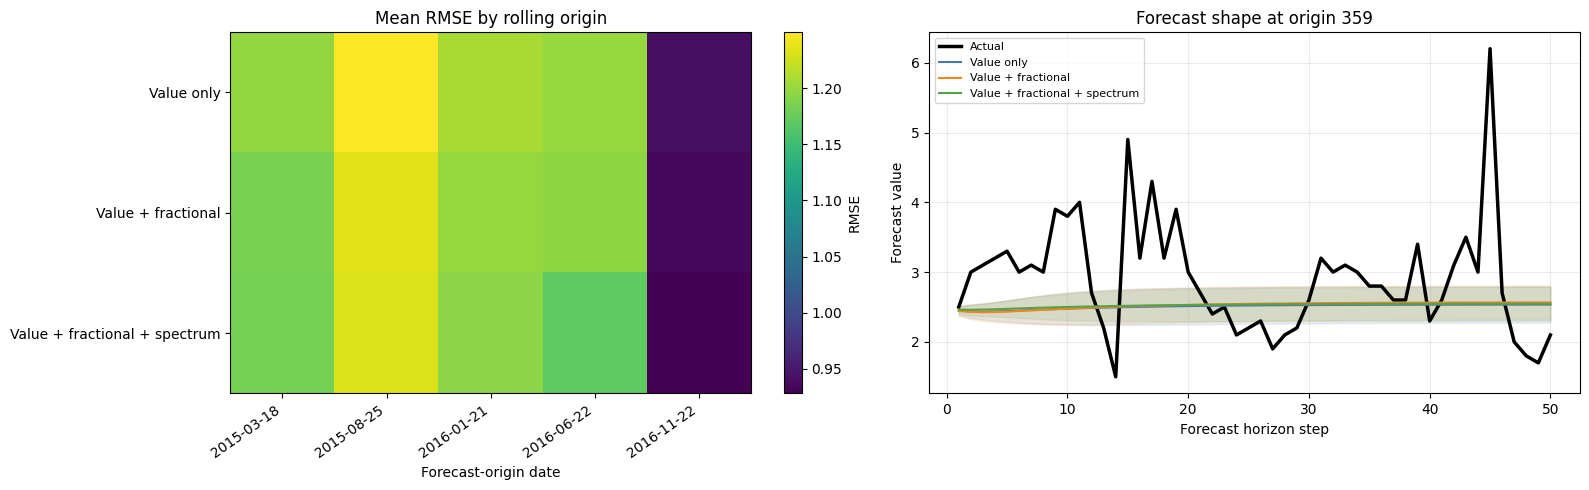

In [16]:
if forecast_panel is not None:
    origin_rmse = (
        forecast_panel.groupby(['variant', 'seed', 'forecast_origin', 'forecast_origin_date'])
        ['error'].apply(lambda values: np.sqrt(np.mean(np.square(values))))
        .rename('rmse').reset_index()
    )
    origin_mean = origin_rmse.groupby(
        ['variant', 'forecast_origin', 'forecast_origin_date'], as_index=False
    )['rmse'].mean()
    heatmap = origin_mean.pivot(index='variant', columns='forecast_origin_date', values='rmse').reindex(MODEL_VARIANTS)

    SELECTED_ORIGIN = int(forecast_panel['forecast_origin'].max())
    selected = forecast_panel[forecast_panel['forecast_origin'] == SELECTED_ORIGIN]
    actual = selected.groupby('horizon_step', as_index=False)['actual'].first()

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    image = axes[0].imshow(heatmap.to_numpy(), aspect='auto', cmap='viridis')
    axes[0].set_yticks(range(len(heatmap.index)), [VARIANT_LABELS[item] for item in heatmap.index])
    axes[0].set_xticks(range(len(heatmap.columns)), heatmap.columns, rotation=35, ha='right')
    axes[0].set_title('Mean RMSE by rolling origin')
    axes[0].set_xlabel('Forecast-origin date')
    fig.colorbar(image, ax=axes[0], label='RMSE')

    axes[1].plot(actual['horizon_step'], actual['actual'], color='black', linewidth=2.5, label='Actual')
    for variant in MODEL_VARIANTS:
        trajectory = (
            selected[selected['variant'] == variant]
            .groupby('horizon_step')['forecast'].agg(['mean', 'std']).reset_index()
        )
        steps = trajectory['horizon_step'].to_numpy()
        mean = trajectory['mean'].to_numpy()
        std = trajectory['std'].fillna(0).to_numpy()
        axes[1].plot(steps, mean, color=VARIANT_COLORS[variant], label=VARIANT_LABELS[variant])
        axes[1].fill_between(steps, mean - std, mean + std, color=VARIANT_COLORS[variant], alpha=0.12)
    axes[1].set_xlabel('Forecast horizon step')
    axes[1].set_ylabel('Forecast value')
    axes[1].set_title(f'Forecast shape at origin {SELECTED_ORIGIN}')
    axes[1].grid(alpha=0.25)
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

### 6.6 Compact interpretation

This final cell states descriptive conclusions only. A candidate is convincing when it lowers mean RMSE, improves most matched seed-origin cases, does not concentrate its gain in just one forecast step or origin, and remains reasonably stable across seeds. Auxiliary-task RMSE or GradNorm weights alone are not evidence of better forecasting.

In [17]:
if run_diagnostics is not None:
    paired_run_rmse = run_diagnostics.pivot(
        index='seed', columns='variant', values='rmse'
    )
    interpretation = []
    for variant in MODEL_VARIANTS:
        values = run_diagnostics.loc[run_diagnostics['variant'] == variant, 'rmse']
        row = {
            'model': VARIANT_LABELS[variant],
            'mean_rmse': values.mean(),
            'seed_std': values.std(ddof=1),
        }
        if variant == 'value_only':
            row.update({'mean_paired_delta': 0.0, 'seed_win_rate': np.nan})
        else:
            delta = paired_run_rmse[variant] - paired_run_rmse['value_only']
            row.update({
                'mean_paired_delta': delta.mean(),
                'seed_win_rate': (delta < 0).mean(),
            })
        interpretation.append(row)
    interpretation = pd.DataFrame(interpretation).sort_values('mean_rmse')
    display(interpretation.style.format({
        'mean_rmse': '{:.4f}',
        'seed_std': '{:.4f}',
        'mean_paired_delta': '{:+.4f}',
        'seed_win_rate': '{:.0%}',
    }))
    winner = interpretation.iloc[0]
    print(
        f"Lowest descriptive mean RMSE: {winner['model']} "
        f"({winner['mean_rmse']:.4f}). Confirm this result in the paired, "
        'horizon-step, and rolling-origin views before drawing a scientific conclusion.'
    )

,model,mean_rmse,seed_std,mean_paired_delta,seed_win_rate
2,Value + fractional + spectrum,1.1468,0.1227,-0.0181,60%
1,Value + fractional,1.1553,0.1330,-0.0096,80%
0,Value only,1.1649,0.1384,+0.0000,nan%


Lowest descriptive mean RMSE: Value + fractional + spectrum (1.1468). Confirm this result in the paired, horizon-step, and rolling-origin views before drawing a scientific conclusion.
